<a href="https://colab.research.google.com/github/kumarsaurabh1817/Final-Computer-Vision-Training/blob/main/week3_detection/day1_detection_concepts/Week3_Day1_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 3 · Day 1 — Detection Concepts

**Goal:** understand what an object detector outputs and how it is scored, before training one tomorrow.

| Concept | What you will build |
|---|---|
| Bounding-box formats | `xyxy`, `xywh`, normalized YOLO `cx cy w h` + converters |
| IoU | Vectorized pairwise IoU, verified against `torchvision.ops.box_iou` |
| NMS | Greedy NMS from scratch, verified against `torchvision.ops.nms` |
| mAP | A COCO-style evaluator (AP@0.5 and AP@0.5:0.95, 101-point interpolation) |
| One-stage vs two-stage | Pretrained **YOLO26** (anchor-free, NMS-free) vs **Faster R-CNN** (anchors + RPN) on the same images |

**Dataset:** [COCO128 on Kaggle](https://www.kaggle.com/datasets/ultralytics/coco128) — the first 128 COCO train2017 images with YOLO-format labels (~7 MB). It downloads automatically below.

> Runtime: **Runtime → Change runtime type → T4 GPU**, then run all cells in order.

## 0 · Install dependencies

In [16]:
import subprocess
import sys


def pip_install(*packages: str) -> None:
    """Install packages into the running interpreter (works in Colab and plain Python)."""
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])


pip_install("ultralytics==8.4.182", "kagglehub==1.0.2")

## 1 · Imports, configuration, and output folder

In [17]:
import json
import shutil
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # headless when run as a script

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
import yaml
from PIL import Image
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights,
    fasterrcnn_resnet50_fpn_v2,
)
from torchvision.transforms.functional import to_tensor
from ultralytics import YOLO

IN_COLAB = "google.colab" in sys.modules
try:
    HERE = Path(__file__).resolve().parent
except NameError:  # running inside a notebook
    HERE = Path.cwd()

OUTPUT_DIR = Path("/content/week3_outputs/day1") if IN_COLAB else HERE.parent / "results" / "day1"
DATA_DIR = Path("/content/datasets") if IN_COLAB else HERE.parent / "data"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
YOLO_WEIGHTS = "yolo26n.pt"  # swap to "yolo11n.pt" if your Ultralytics build lacks YOLO26
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__} | device={DEVICE}")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Outputs ->", OUTPUT_DIR)


def save_fig(fig, name: str) -> None:
    """Save a figure to OUTPUT_DIR and show it inline when in a notebook."""
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
    print(f"saved -> {path}")

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device=cuda
GPU: Tesla T4
Outputs -> /content/week3_outputs/day1


## 2 · Download COCO128 from Kaggle

`kagglehub` downloads public datasets without an API token. If Kaggle is unreachable, the cell falls back to the identical zip that Ultralytics hosts on GitHub. The data is copied to a writable folder because Ultralytics writes a `labels/*.cache` file next to the labels.

In [18]:
KAGGLE_HANDLE = "ultralytics/coco128"
COCO128_ZIP = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"


def locate_coco128(root: Path) -> Path:
    for cand in [root / "coco128", root, *root.rglob("coco128")]:
        if (cand / "images" / "train2017").is_dir() and (cand / "labels" / "train2017").is_dir():
            return cand
    raise FileNotFoundError(f"coco128/images/train2017 not found below {root}")


def get_coco128() -> Path:
    target = DATA_DIR / "coco128"
    if (target / "images" / "train2017").is_dir():
        return target
    try:
        import kagglehub

        src = locate_coco128(Path(kagglehub.dataset_download(KAGGLE_HANDLE)))
        shutil.copytree(src, target)
    except Exception as exc:  # network / API issues -> GitHub mirror
        print(f"Kaggle download failed ({exc}); using the Ultralytics GitHub mirror")
        zip_path = DATA_DIR / "coco128.zip"
        urllib.request.urlretrieve(COCO128_ZIP, zip_path)
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(DATA_DIR)
    return locate_coco128(DATA_DIR)


COCO_ROOT = get_coco128()
IMAGE_PATHS = sorted((COCO_ROOT / "images" / "train2017").glob("*.jpg"))
print(f"COCO128 at {COCO_ROOT} — {len(IMAGE_PATHS)} images")

COCO128 at /content/datasets/coco128 — 128 images


## 3 · Bounding-box formats

| Format | Values | Used by |
|---|---|---|
| `xyxy` | `x1, y1, x2, y2` in pixels | torchvision, most metrics code |
| `xywh` | `x1, y1, w, h` in pixels | COCO JSON annotations |
| YOLO `cxcywh` | `cx, cy, w, h` **normalized 0–1** | YOLO `.txt` labels (one line per object, class id first) |

Most detection bugs are silent format mix-ups, so every converter below is round-trip tested.

In [19]:
def xyxy_to_xywh(b: np.ndarray) -> np.ndarray:
    return np.stack([b[:, 0], b[:, 1], b[:, 2] - b[:, 0], b[:, 3] - b[:, 1]], axis=1)


def xywh_to_xyxy(b: np.ndarray) -> np.ndarray:
    return np.stack([b[:, 0], b[:, 1], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]], axis=1)


def xyxy_to_cxcywh(b: np.ndarray) -> np.ndarray:
    w, h = b[:, 2] - b[:, 0], b[:, 3] - b[:, 1]
    return np.stack([b[:, 0] + w / 2, b[:, 1] + h / 2, w, h], axis=1)


def cxcywh_to_xyxy(b: np.ndarray) -> np.ndarray:
    return np.stack(
        [b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], axis=1
    )


def yolo_to_xyxy(b_norm: np.ndarray, img_w: int, img_h: int) -> np.ndarray:
    """Normalized YOLO cx,cy,w,h -> pixel xyxy."""
    return cxcywh_to_xyxy(b_norm * np.array([img_w, img_h, img_w, img_h], dtype=float))


def xyxy_to_yolo(b: np.ndarray, img_w: int, img_h: int) -> np.ndarray:
    return xyxy_to_cxcywh(b) / np.array([img_w, img_h, img_w, img_h], dtype=float)


demo = np.array([[100.0, 50.0, 300.0, 250.0]])
print("xyxy  :", demo[0])
print("xywh  :", xyxy_to_xywh(demo)[0])
print("cxcywh:", xyxy_to_cxcywh(demo)[0])
print("YOLO (640x480 image):", np.round(xyxy_to_yolo(demo, 640, 480)[0], 4))

top_left = rng.uniform(0, 440, size=(1000, 2))
random_boxes = np.concatenate([top_left, top_left + rng.uniform(5, 200, size=(1000, 2))], axis=1)  # valid xyxy
assert np.allclose(xywh_to_xyxy(xyxy_to_xywh(random_boxes)), random_boxes)
assert np.allclose(cxcywh_to_xyxy(xyxy_to_cxcywh(random_boxes)), random_boxes)
assert np.allclose(yolo_to_xyxy(xyxy_to_yolo(random_boxes, 640, 480), 640, 480), random_boxes)
print("All box-format round trips passed.")

xyxy  : [        100          50         300         250]
xywh  : [        100          50         200         200]
cxcywh: [        200         150         200         200]
YOLO (640x480 image): [     0.3125      0.3125      0.3125      0.4167]
All box-format round trips passed.


## 4 · Intersection over Union (IoU)

$$\text{IoU}(A,B)=\frac{|A\cap B|}{|A\cup B|}$$

IoU decides whether a prediction "hits" a ground-truth box. A detection with IoU ≥ 0.5 counts as a true positive for AP@0.5; COCO's headline metric averages over thresholds 0.50…0.95, rewarding tight localization.

pairwise_iou matches torchvision.ops.box_iou


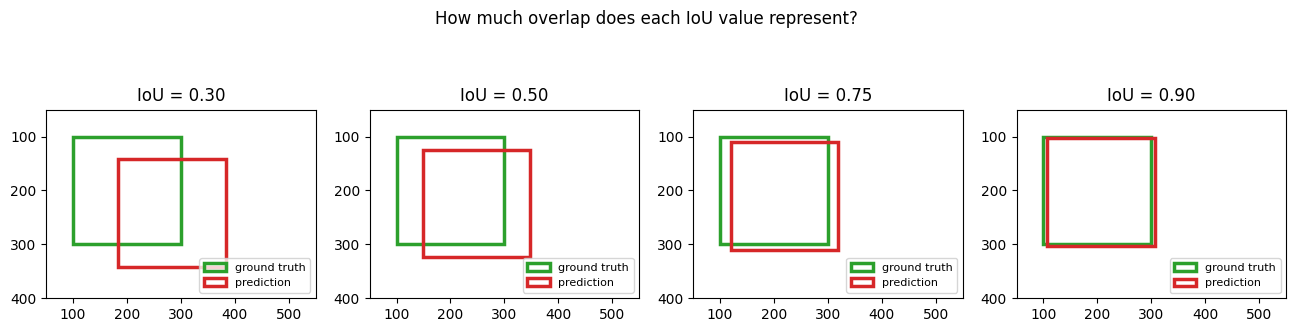

saved -> /content/week3_outputs/day1/day1_iou_examples.png


In [20]:
def box_area(b: np.ndarray) -> np.ndarray:
    return np.clip(b[:, 2] - b[:, 0], 0, None) * np.clip(b[:, 3] - b[:, 1], 0, None)


def pairwise_iou(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """IoU matrix of shape (len(a), len(b)) for xyxy boxes."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    top_left = np.maximum(a[:, None, :2], b[None, :, :2])
    bottom_right = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(bottom_right - top_left, 0, None)
    inter = wh[..., 0] * wh[..., 1]
    union = box_area(a)[:, None] + box_area(b)[None, :] - inter
    return inter / np.maximum(union, 1e-9)


ours = pairwise_iou(random_boxes[:50], random_boxes[50:120])
reference = torchvision.ops.box_iou(torch.tensor(random_boxes[:50]), torch.tensor(random_boxes[50:120])).numpy()
assert np.allclose(ours, reference, atol=1e-6)
print("pairwise_iou matches torchvision.ops.box_iou")

# Visual intuition: the same box shifted until IoU hits a target value
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
base = np.array([[100.0, 100.0, 300.0, 300.0]])
for ax, target in zip(axes, [0.3, 0.5, 0.75, 0.9]):
    shifts = np.linspace(0, 200, 4001)
    ious = [pairwise_iou(base, base + [s, s / 2, s, s / 2])[0, 0] for s in shifts]
    shift = shifts[int(np.argmin(np.abs(np.array(ious) - target)))]
    other = base + [shift, shift / 2, shift, shift / 2]
    for box, color, label in [(base[0], "tab:green", "ground truth"), (other[0], "tab:red", "prediction")]:
        ax.add_patch(patches.Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, lw=2.5, ec=color, label=label))
    ax.set_xlim(50, 550)
    ax.set_ylim(400, 50)
    ax.set_aspect("equal")
    ax.set_title(f"IoU = {pairwise_iou(base, other)[0, 0]:.2f}")
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("How much overlap does each IoU value represent?")
save_fig(fig, "day1_iou_examples.png")

## 5 · Read YOLO labels and validate them visually

A YOLO label file has one row per object: `class_id cx cy w h` (normalized). Always draw a few labels before trusting a dataset — this is the habit the week's note warns about.

929 labelled objects across 71 classes


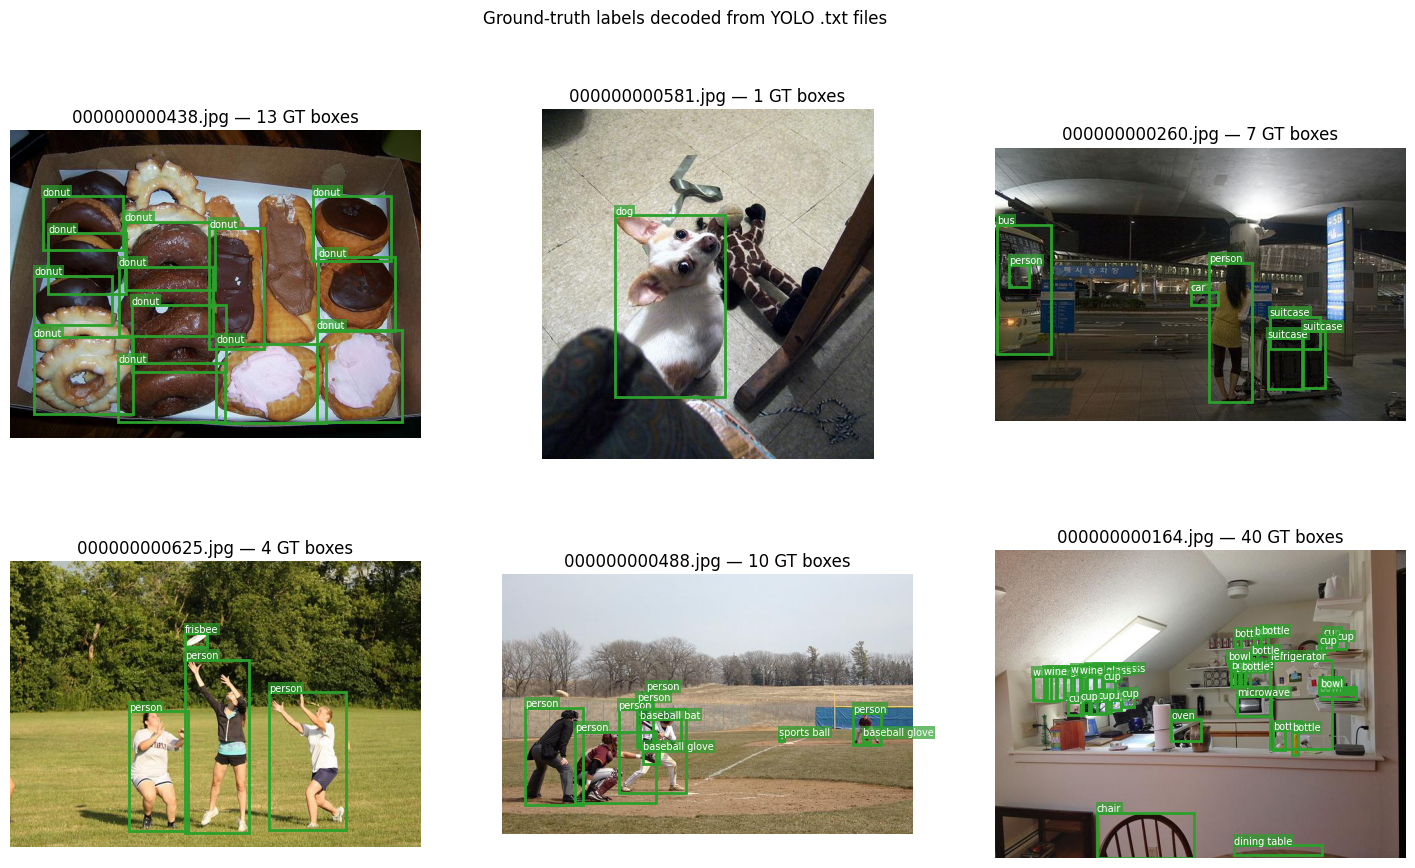

saved -> /content/week3_outputs/day1/day1_ground_truth_check.png


In [21]:
YOLO_MODEL = YOLO(YOLO_WEIGHTS)
CLASS_NAMES: dict[int, str] = YOLO_MODEL.names  # 80 COCO classes, same order as coco128 labels


def load_ground_truth(img_path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Return (class_ids, xyxy pixel boxes) for one coco128 image."""
    label_path = COCO_ROOT / "labels" / "train2017" / (img_path.stem + ".txt")
    with Image.open(img_path) as im:
        w, h = im.size
    if not label_path.exists() or label_path.stat().st_size == 0:
        return np.zeros(0, dtype=int), np.zeros((0, 4))
    rows = np.loadtxt(label_path, ndmin=2)
    return rows[:, 0].astype(int), yolo_to_xyxy(rows[:, 1:5], w, h)


GROUND_TRUTH = {p.stem: load_ground_truth(p) for p in IMAGE_PATHS}
n_objects = sum(len(c) for c, _ in GROUND_TRUTH.values())
classes_present = sorted({int(c) for cls, _ in GROUND_TRUTH.values() for c in cls})
print(f"{n_objects} labelled objects across {len(classes_present)} classes")


def draw_boxes(ax, boxes, labels, color, scores=None):
    for i, (box, label) in enumerate(zip(boxes, labels)):
        x1, y1, x2, y2 = box
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2, ec=color))
        text = label if scores is None else f"{label} {scores[i]:.2f}"
        ax.text(x1, y1 - 2, text, color="white", fontsize=7, bbox=dict(facecolor=color, alpha=0.7, pad=1, lw=0))


sample_paths = [IMAGE_PATHS[i] for i in rng.choice(len(IMAGE_PATHS), 6, replace=False)]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, path in zip(axes.flat, sample_paths):
    cls, boxes = GROUND_TRUTH[path.stem]
    ax.imshow(Image.open(path).convert("RGB"))
    draw_boxes(ax, boxes, [CLASS_NAMES[c] for c in cls], "tab:green")
    ax.set_title(f"{path.name} — {len(cls)} GT boxes")
    ax.axis("off")
fig.suptitle("Ground-truth labels decoded from YOLO .txt files")
save_fig(fig, "day1_ground_truth_check.png")

## 6 · Run a pretrained YOLO26 detector and inspect its raw output

Each `Results` object exposes `boxes.xyxy`, `boxes.conf`, and `boxes.cls`. YOLO26 is **anchor-free** (it predicts box geometry directly per grid cell) and **end-to-end**: its one-to-one head emits one box per object, so no NMS post-processing is needed.

Image: 000000000438.jpg | original shape: (480, 640)
boxes.xyxy : (19, 4)
boxes.conf : [       0.88       0.878       0.871        0.84       0.814]
boxes.cls  : ['donut', 'donut', 'donut', 'donut', 'donut']
speed (ms) : {'preprocess': 1.3, 'inference': 6.6, 'postprocess': 2.7}


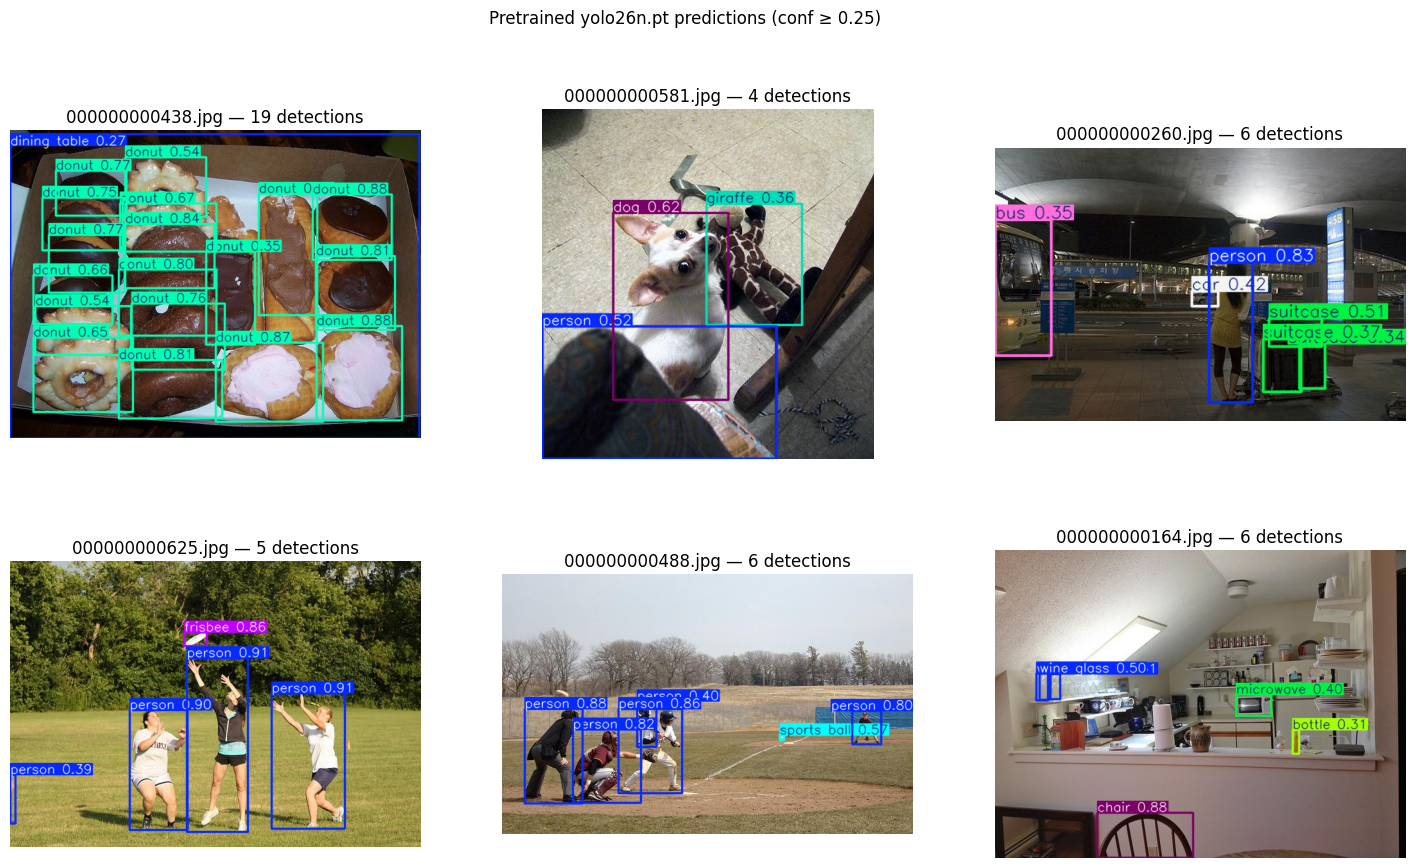

saved -> /content/week3_outputs/day1/day1_yolo_predictions.png


In [22]:
results = YOLO_MODEL.predict([str(p) for p in sample_paths], conf=0.25, verbose=False, device=0 if DEVICE.type == "cuda" else "cpu")
first = results[0]
print("Image:", Path(first.path).name, "| original shape:", first.orig_shape)
print("boxes.xyxy :", tuple(first.boxes.xyxy.shape))
print("boxes.conf :", first.boxes.conf[:5].cpu().numpy().round(3))
print("boxes.cls  :", [CLASS_NAMES[int(c)] for c in first.boxes.cls[:5]])
print("speed (ms) :", {k: round(v, 1) for k, v in first.speed.items()})

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, res in zip(axes.flat, results):
    ax.imshow(res.plot()[..., ::-1])  # plot() returns BGR
    ax.set_title(f"{Path(res.path).name} — {len(res.boxes)} detections")
    ax.axis("off")
fig.suptitle(f"Pretrained {YOLO_WEIGHTS} predictions (conf ≥ 0.25)")
save_fig(fig, "day1_yolo_predictions.png")

## 7 · Non-Maximum Suppression (NMS) from scratch

Classic detectors (Faster R-CNN, YOLOv3–v8, YOLO11) emit many overlapping candidates per object, and **NMS** keeps the highest-scoring box while discarding neighbours above an IoU threshold. We simulate a raw, duplicate-heavy output by jittering YOLO's detections, then check our NMS against torchvision.

152 raw candidates -> 19 after NMS (torchvision agrees)


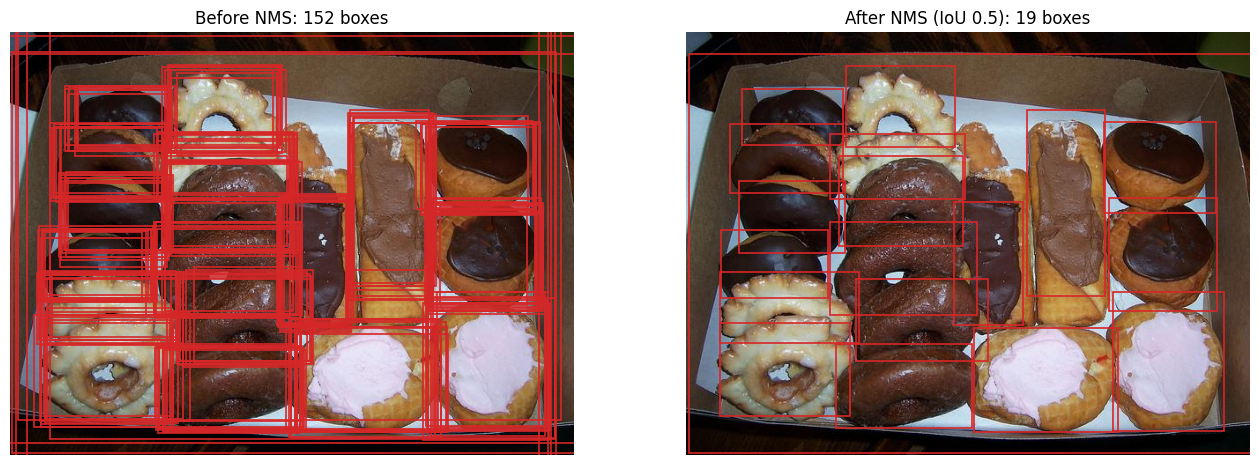

saved -> /content/week3_outputs/day1/day1_nms_before_after.png


In [23]:
def nms(boxes: np.ndarray, scores: np.ndarray, iou_threshold: float) -> np.ndarray:
    """Greedy NMS. Returns kept indices sorted by descending score."""
    order = np.argsort(-scores)
    keep = []
    while order.size:
        best = order[0]
        keep.append(best)
        if order.size == 1:
            break
        ious = pairwise_iou(boxes[best : best + 1], boxes[order[1:]])[0]
        order = order[1:][ious <= iou_threshold]
    return np.array(keep, dtype=int)


det_boxes = first.boxes.xyxy.cpu().numpy()
det_scores = first.boxes.conf.cpu().numpy()
if len(det_boxes) == 0:  # pick any image with detections
    first = next(r for r in results if len(r.boxes))
    det_boxes, det_scores = first.boxes.xyxy.cpu().numpy(), first.boxes.conf.cpu().numpy()

copies = 8
sizes = np.repeat(np.stack([det_boxes[:, 2] - det_boxes[:, 0], det_boxes[:, 3] - det_boxes[:, 1]] * 2, axis=1), copies, axis=0)
raw_boxes = np.repeat(det_boxes, copies, axis=0) + rng.normal(0, 0.04, size=sizes.shape) * sizes
raw_scores = np.clip(np.repeat(det_scores, copies) * rng.uniform(0.6, 1.0, size=len(raw_boxes)), 0, 1)

keep_ours = nms(raw_boxes, raw_scores, iou_threshold=0.5)
keep_tv = torchvision.ops.nms(torch.tensor(raw_boxes, dtype=torch.float32), torch.tensor(raw_scores, dtype=torch.float32), 0.5).numpy()
assert set(keep_ours.tolist()) == set(keep_tv.tolist()), "NMS mismatch vs torchvision"
print(f"{len(raw_boxes)} raw candidates -> {len(keep_ours)} after NMS (torchvision agrees)")

img = Image.open(first.path).convert("RGB")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, idx, title in [(axes[0], np.arange(len(raw_boxes)), "Before NMS"), (axes[1], keep_ours, "After NMS (IoU 0.5)")]:
    ax.imshow(img)
    for box in raw_boxes[idx]:
        ax.add_patch(patches.Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, lw=1.2, ec="tab:red"))
    ax.set_title(f"{title}: {len(idx)} boxes")
    ax.axis("off")
save_fig(fig, "day1_nms_before_after.png")

## 8 · mAP from scratch

For each class and IoU threshold:
1. Sort all predictions of that class (across all images) by confidence.
2. Greedily match each prediction to the best-overlapping **unmatched** ground truth with IoU ≥ threshold → TP, otherwise FP.
3. Build the cumulative precision/recall curve, take its monotone envelope, and average precision at 101 recall points (COCO style).

**mAP@0.5** averages AP over classes at IoU 0.5; **mAP@0.5:0.95** also averages over 10 IoU thresholds.

In [24]:
IOU_THRESHOLDS = np.linspace(0.5, 0.95, 10)


def match_predictions(pred_boxes, pred_scores, gt_boxes, iou_threshold) -> np.ndarray:
    """Return a TP flag (1/0) per prediction for one image and one class."""
    tp = np.zeros(len(pred_boxes))
    if len(pred_boxes) == 0 or len(gt_boxes) == 0:
        return tp
    ious = pairwise_iou(pred_boxes, gt_boxes)
    taken = np.zeros(len(gt_boxes), dtype=bool)
    for i in np.argsort(-pred_scores):
        candidates = np.where(~taken & (ious[i] >= iou_threshold))[0]
        if candidates.size:
            j = candidates[np.argmax(ious[i, candidates])]
            taken[j] = True
            tp[i] = 1
    return tp


def average_precision(tp: np.ndarray, scores: np.ndarray, n_gt: int):
    """COCO 101-point interpolated AP. Returns (ap, precision, recall)."""
    if n_gt == 0:
        return np.nan, np.array([]), np.array([])
    if len(tp) == 0:
        return 0.0, np.array([]), np.array([])
    order = np.argsort(-scores, kind="stable")
    tp_cum = np.cumsum(tp[order])
    fp_cum = np.cumsum(1 - tp[order])
    recall = tp_cum / n_gt
    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1e-9)
    mrec = np.concatenate([[0.0], recall, [1.0]])
    mpre = np.concatenate([[0.0], precision, [0.0]])
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))  # precision envelope
    recall_points = np.linspace(0, 1, 101)
    idx = np.searchsorted(mrec, recall_points, side="left")
    ap = float(np.mean(mpre[np.clip(idx, 0, len(mpre) - 1)]))
    return ap, precision, recall


def evaluate_detections(predictions: dict, ground_truth: dict) -> dict:
    """predictions[img] = (cls, boxes, scores); ground_truth[img] = (cls, boxes)."""
    gt_classes = sorted({int(c) for cls, _ in ground_truth.values() for c in cls})
    ap_table = np.full((len(gt_classes), len(IOU_THRESHOLDS)), np.nan)
    pr_curves = {}
    for ci, c in enumerate(gt_classes):
        n_gt = sum(int((cls == c).sum()) for cls, _ in ground_truth.values())
        for ti, thr in enumerate(IOU_THRESHOLDS):
            tps, scores = [], []
            for img_id, (g_cls, g_boxes) in ground_truth.items():
                p_cls, p_boxes, p_scores = predictions.get(img_id, (np.zeros(0), np.zeros((0, 4)), np.zeros(0)))
                pm = p_cls == c
                tps.append(match_predictions(p_boxes[pm], p_scores[pm], g_boxes[g_cls == c], thr))
                scores.append(p_scores[pm])
            ap, precision, recall = average_precision(np.concatenate(tps), np.concatenate(scores), n_gt)
            ap_table[ci, ti] = ap
            if ti == 0:
                pr_curves[c] = (precision, recall)
    return {
        "classes": gt_classes,
        "ap_table": ap_table,
        "map50": float(np.nanmean(ap_table[:, 0])),
        "map50_95": float(np.nanmean(ap_table)),
        "pr_curves": pr_curves,
    }


def yolo_predictions(model: YOLO, paths: list[Path], conf: float = 0.001) -> tuple[dict, float]:
    """Run YOLO image-by-image; return predictions dict and mean latency (ms/img)."""
    preds, times = {}, []
    device = 0 if DEVICE.type == "cuda" else "cpu"
    model.predict(str(paths[0]), conf=conf, verbose=False, device=device)  # warm-up
    for p in paths:
        t0 = time.perf_counter()
        r = model.predict(str(p), conf=conf, max_det=300, verbose=False, device=device)[0]
        times.append((time.perf_counter() - t0) * 1000)
        preds[p.stem] = (
            r.boxes.cls.cpu().numpy().astype(int),
            r.boxes.xyxy.cpu().numpy(),
            r.boxes.conf.cpu().numpy(),
        )
    return preds, float(np.mean(times))


YOLO_PREDS, yolo_ms = yolo_predictions(YOLO_MODEL, IMAGE_PATHS)
yolo_eval = evaluate_detections(YOLO_PREDS, GROUND_TRUTH)
print(f"Our evaluator -> {YOLO_WEIGHTS}: mAP@0.5 = {yolo_eval['map50']:.3f} | mAP@0.5:0.95 = {yolo_eval['map50_95']:.3f}")
print(f"Mean latency: {yolo_ms:.1f} ms/img (batch=1, incl. pre/post-processing)")

Our evaluator -> yolo26n.pt: mAP@0.5 = 0.633 | mAP@0.5:0.95 = 0.474
Mean latency: 32.6 ms/img (batch=1, incl. pre/post-processing)


### Cross-check against Ultralytics' own validator

Numbers should be close but not identical: Ultralytics matches predictions to ground truth with a slightly different assignment procedure and evaluates at a letterboxed resolution. If you see a large gap, suspect a box-format bug.

In [25]:
data_yaml = OUTPUT_DIR / "coco128_kaggle.yaml"
with open(data_yaml, "w") as f:
    yaml.safe_dump(
        {"path": str(COCO_ROOT), "train": "images/train2017", "val": "images/train2017", "names": CLASS_NAMES},
        f,
        sort_keys=False,
    )

val_metrics = YOLO_MODEL.val(
    data=str(data_yaml), imgsz=640, batch=16, conf=0.001, plots=False, verbose=False,
    project=str(OUTPUT_DIR), name="ultralytics_val", exist_ok=True,
    device=0 if DEVICE.type == "cuda" else "cpu",
)
print(f"Ultralytics -> mAP@0.5 = {val_metrics.box.map50:.3f} | mAP@0.5:0.95 = {val_metrics.box.map:.3f}")
print(f"Ours        -> mAP@0.5 = {yolo_eval['map50']:.3f} | mAP@0.5:0.95 = {yolo_eval['map50_95']:.3f}")

Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2162.8±820.1 MB/s, size: 52.3 KB)
val: Scanning /content/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 35.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 6.3it/s 1.3s
                   all        128        929      0.734      0.549      0.649      0.486
Speed: 0.8ms preprocess, 4.1ms inference, 0.0ms loss, 1.3ms postprocess per image
Ultralytics -> mAP@0.5 = 0.649 | mAP@0.5:0.95 = 0.486
Ours        -> mAP@0.5 = 0.633 | mAP@0.5:0.95 = 0.474


### Per-class AP and precision–recall curves

The PR curve is what AP summarizes: AP is (approximately) the area under the precision envelope.

class              #GT    AP50  AP50-95
train                3   1.000    0.900
airplane             6   1.000    0.921
horse                2   1.000    0.802
stop sign            2   1.000    0.650
bird                16   1.000    0.700
cat                  4   1.000    0.925
zebra                4   1.000    0.975
bear                 1   1.000    1.000
suitcase             4   1.000    0.683
skis                 1   1.000    0.209
...
baseball bat         4   0.147    0.061
handbag             19   0.116    0.058
banana               1   0.111    0.089
mouse                2   0.000    0.000
scissors             1   0.000    0.000


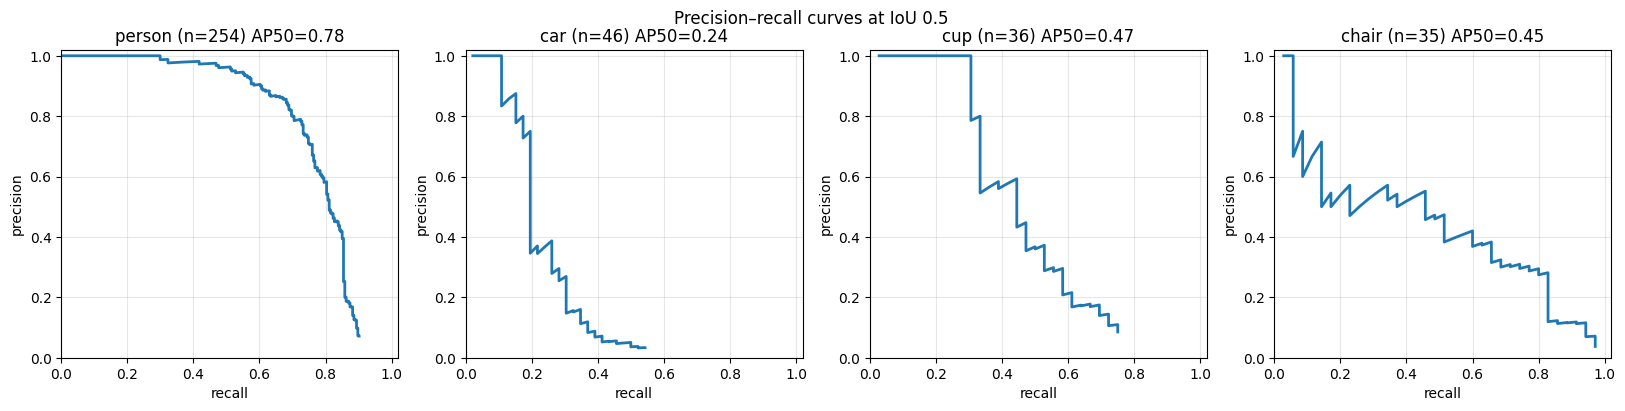

saved -> /content/week3_outputs/day1/day1_pr_curves.png


In [26]:
ap50 = yolo_eval["ap_table"][:, 0]
order = np.argsort(-ap50)
print(f"{'class':<16}{'#GT':>6}{'AP50':>8}{'AP50-95':>9}")
for ci in order[:10]:
    c = yolo_eval["classes"][ci]
    n_gt = sum(int((cls == c).sum()) for cls, _ in GROUND_TRUTH.values())
    print(f"{CLASS_NAMES[c]:<16}{n_gt:>6}{ap50[ci]:>8.3f}{np.nanmean(yolo_eval['ap_table'][ci]):>9.3f}")
print("...")
for ci in order[-5:]:
    c = yolo_eval["classes"][ci]
    n_gt = sum(int((cls == c).sum()) for cls, _ in GROUND_TRUTH.values())
    print(f"{CLASS_NAMES[c]:<16}{n_gt:>6}{ap50[ci]:>8.3f}{np.nanmean(yolo_eval['ap_table'][ci]):>9.3f}")

class_counts = {c: sum(int((cls == c).sum()) for cls, _ in GROUND_TRUTH.values()) for c in yolo_eval["classes"]}
top_classes = sorted(class_counts, key=class_counts.get, reverse=True)[:4]
fig, axes = plt.subplots(1, len(top_classes), figsize=(5 * len(top_classes), 4))
for ax, c in zip(np.atleast_1d(axes), top_classes):
    precision, recall = yolo_eval["pr_curves"][c]
    ci = yolo_eval["classes"].index(c)
    ax.plot(recall, precision, lw=2)
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_title(f"{CLASS_NAMES[c]} (n={class_counts[c]}) AP50={ap50[ci]:.2f}")
    ax.grid(alpha=0.3)
fig.suptitle("Precision–recall curves at IoU 0.5")
save_fig(fig, "day1_pr_curves.png")

### Confidence threshold trade-off

mAP is threshold-free, but a deployed detector needs one confidence cut-off. Sweep it and watch precision rise while recall falls (IoU 0.5, all classes pooled).

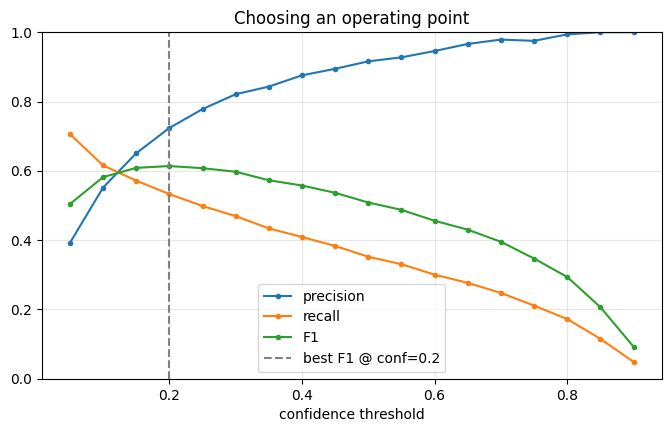

saved -> /content/week3_outputs/day1/day1_conf_sweep.png


In [27]:
def pooled_pr_at_conf(predictions, ground_truth, conf_threshold, iou_threshold=0.5):
    tp_total = fp_total = 0
    n_gt = sum(len(c) for c, _ in ground_truth.values())
    for img_id, (g_cls, g_boxes) in ground_truth.items():
        p_cls, p_boxes, p_scores = predictions[img_id]
        keep = p_scores >= conf_threshold
        for c in np.unique(p_cls[keep]):
            pm = keep & (p_cls == c)
            tp = match_predictions(p_boxes[pm], p_scores[pm], g_boxes[g_cls == c], iou_threshold)
            tp_total += tp.sum()
            fp_total += len(tp) - tp.sum()
    precision = tp_total / max(tp_total + fp_total, 1)
    recall = tp_total / max(n_gt, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    return precision, recall, f1


conf_grid = np.round(np.arange(0.05, 0.95, 0.05), 2)
sweep = np.array([pooled_pr_at_conf(YOLO_PREDS, GROUND_TRUTH, t) for t in conf_grid])
best_idx = int(np.argmax(sweep[:, 2]))
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, label in enumerate(["precision", "recall", "F1"]):
    ax.plot(conf_grid, sweep[:, k], marker="o", ms=3, label=label)
ax.axvline(conf_grid[best_idx], ls="--", c="gray", label=f"best F1 @ conf={conf_grid[best_idx]}")
ax.set_xlabel("confidence threshold")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("Choosing an operating point")
save_fig(fig, "day1_conf_sweep.png")

## 9 · One-stage vs two-stage: YOLO26 vs Faster R-CNN

| | YOLO26 (one-stage) | Faster R-CNN (two-stage) |
|---|---|---|
| Stage 1 | Dense prediction per grid cell | Region Proposal Network scores **anchors** and proposes regions |
| Stage 2 | — | RoIAlign crops features per proposal, then classifies + refines boxes |
| Anchors | Anchor-free | Anchor-based (sizes × aspect ratios per FPN level) |
| Post-processing | NMS-free (one-to-one head) | NMS in the RPN and the final head |

Both are evaluated with **our** evaluator on the same images. Faster R-CNN uses the 91-id COCO label space, so labels are mapped to YOLO's 80 classes by name.

> Caveat: COCO128 comes from COCO *train2017*, which both models saw during training. Absolute mAP is optimistic; the comparison and the latency gap are the lesson.

In [28]:
frcnn_weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
frcnn = fasterrcnn_resnet50_fpn_v2(weights=frcnn_weights, box_score_thresh=0.001, box_detections_per_img=300)
frcnn = frcnn.to(DEVICE).eval()

anchor_gen = frcnn.rpn.anchor_generator
print("Faster R-CNN anchor sizes per FPN level :", anchor_gen.sizes)
print("Aspect ratios per level                 :", anchor_gen.aspect_ratios[0])
print("Anchors per feature-map location        :", anchor_gen.num_anchors_per_location())

name_to_yolo = {name: idx for idx, name in CLASS_NAMES.items()}
tv_to_yolo = np.array([name_to_yolo.get(n, -1) for n in frcnn_weights.meta["categories"]])
print(f"Mapped {int((tv_to_yolo >= 0).sum())}/80 torchvision categories onto YOLO class ids")


@torch.no_grad()
def frcnn_predictions(paths: list[Path]) -> tuple[dict, float]:
    preds, times = {}, []
    frcnn([to_tensor(Image.open(paths[0]).convert("RGB")).to(DEVICE)])  # warm-up
    for p in paths:
        x = to_tensor(Image.open(p).convert("RGB")).to(DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        out = frcnn([x])[0]
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)
        cls = tv_to_yolo[out["labels"].cpu().numpy()]
        keep = cls >= 0
        preds[p.stem] = (cls[keep], out["boxes"].cpu().numpy()[keep], out["scores"].cpu().numpy()[keep])
    return preds, float(np.mean(times))


FRCNN_PREDS, frcnn_ms = frcnn_predictions(IMAGE_PATHS)
frcnn_eval = evaluate_detections(FRCNN_PREDS, GROUND_TRUTH)


def n_params(module: torch.nn.Module) -> float:
    return sum(p.numel() for p in module.parameters()) / 1e6


comparison = [
    {"model": YOLO_WEIGHTS, "type": "one-stage, anchor-free, NMS-free", "params_M": round(n_params(YOLO_MODEL.model), 1),
     "mAP50": round(yolo_eval["map50"], 3), "mAP50_95": round(yolo_eval["map50_95"], 3), "ms_per_img": round(yolo_ms, 1)},
    {"model": "fasterrcnn_resnet50_fpn_v2", "type": "two-stage, anchor-based, NMS", "params_M": round(n_params(frcnn), 1),
     "mAP50": round(frcnn_eval["map50"], 3), "mAP50_95": round(frcnn_eval["map50_95"], 3), "ms_per_img": round(frcnn_ms, 1)},
]
print(f"\n{'model':<30}{'params(M)':>10}{'mAP50':>8}{'mAP50-95':>10}{'ms/img':>9}  type")
for row in comparison:
    print(f"{row['model']:<30}{row['params_M']:>10}{row['mAP50']:>8}{row['mAP50_95']:>10}{row['ms_per_img']:>9}  {row['type']}")

Faster R-CNN anchor sizes per FPN level : ((32,), (64,), (128,), (256,), (512,))
Aspect ratios per level                 : (0.5, 1.0, 2.0)
Anchors per feature-map location        : [3, 3, 3, 3, 3]
Mapped 80/80 torchvision categories onto YOLO class ids

model                          params(M)   mAP50  mAP50-95   ms/img  type
yolo26n.pt                           2.6   0.633     0.474     32.6  one-stage, anchor-free, NMS-free
fasterrcnn_resnet50_fpn_v2          43.7   0.788     0.578    268.6  two-stage, anchor-based, NMS


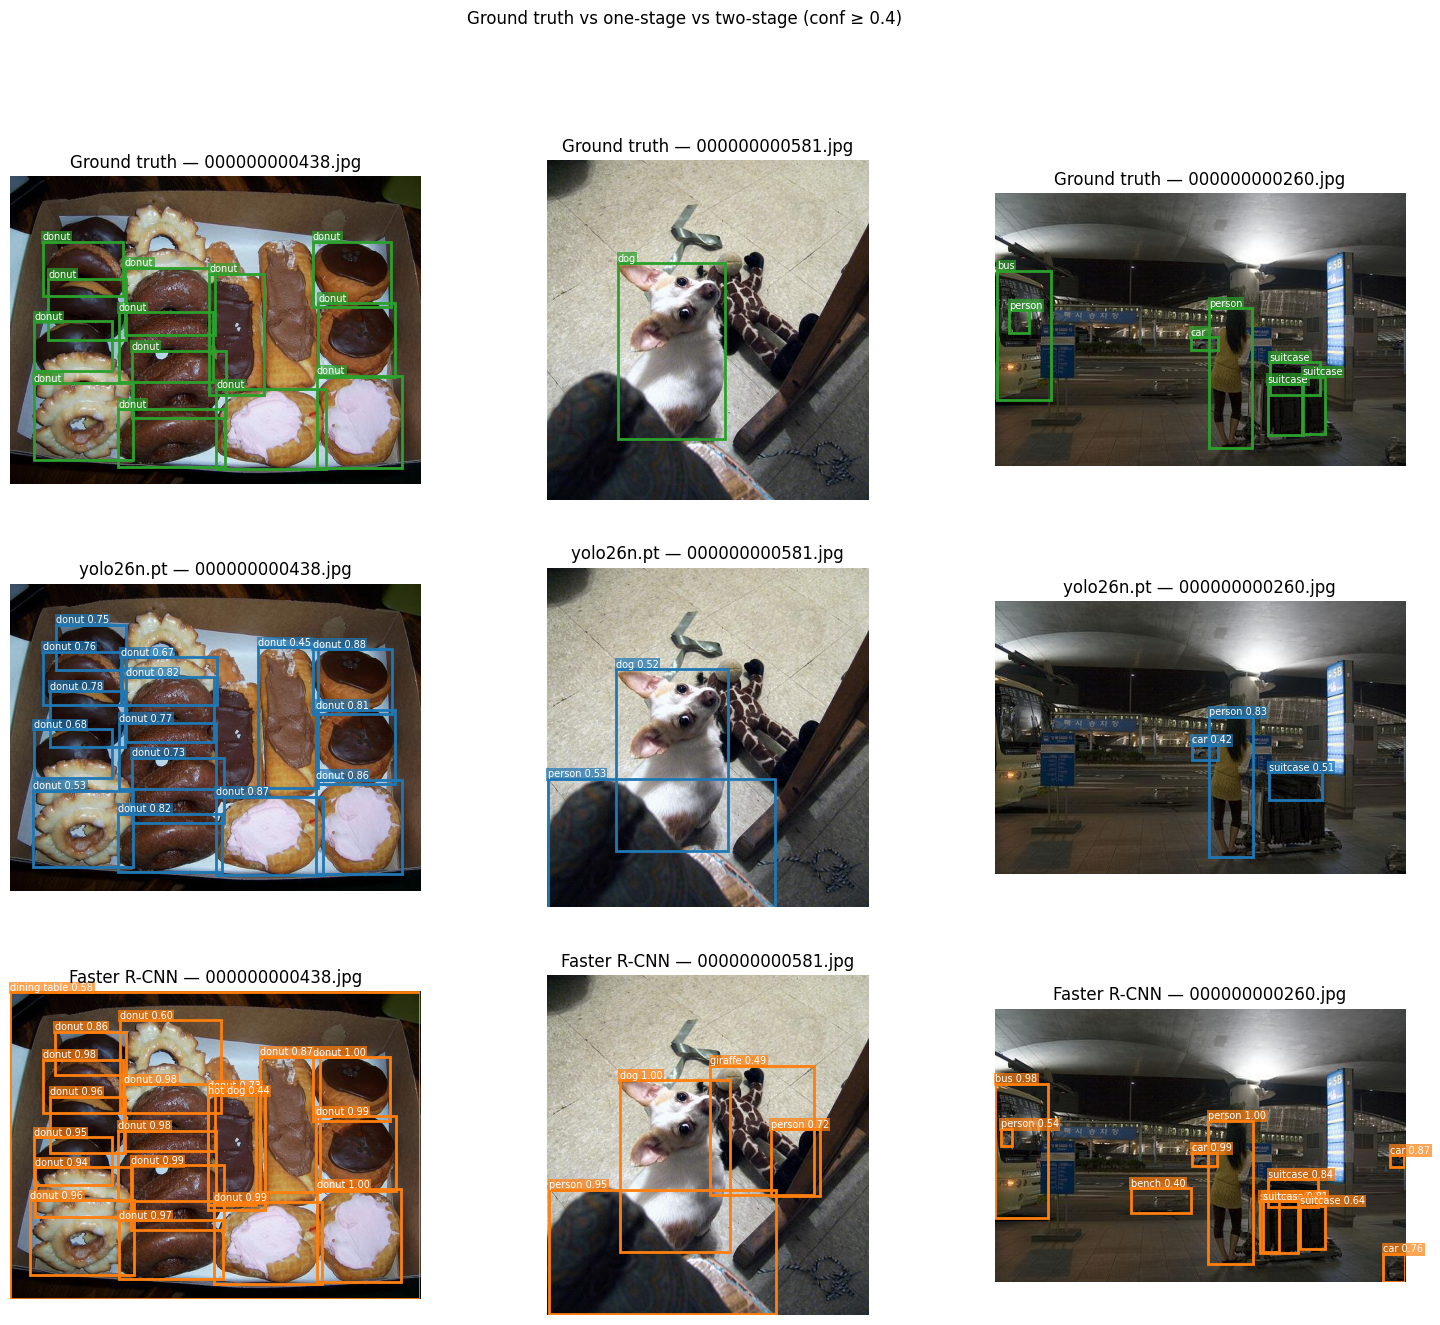

saved -> /content/week3_outputs/day1/day1_one_vs_two_stage.png


In [29]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
for col, path in enumerate(sample_paths[:3]):
    image = Image.open(path).convert("RGB")
    g_cls, g_boxes = GROUND_TRUTH[path.stem]
    panels = [("Ground truth", g_cls, g_boxes, None, "tab:green")]
    for name, preds, color in [(YOLO_WEIGHTS, YOLO_PREDS, "tab:blue"), ("Faster R-CNN", FRCNN_PREDS, "tab:orange")]:
        p_cls, p_boxes, p_scores = preds[path.stem]
        keep = p_scores >= 0.4
        panels.append((name, p_cls[keep], p_boxes[keep], p_scores[keep], color))
    for row, (title, cls, boxes, scores, color) in enumerate(panels):
        ax = axes[row, col]
        ax.imshow(image)
        draw_boxes(ax, boxes, [CLASS_NAMES[int(c)] for c in cls], color, scores)
        ax.set_title(f"{title} — {path.name}")
        ax.axis("off")
fig.suptitle("Ground truth vs one-stage vs two-stage (conf ≥ 0.4)")
save_fig(fig, "day1_one_vs_two_stage.png")

## 10 · Save results

In [30]:
summary = {
    "dataset": "ultralytics/coco128 (Kaggle)",
    "images": len(IMAGE_PATHS),
    "objects": n_objects,
    "our_evaluator": {
        YOLO_WEIGHTS: {"mAP50": yolo_eval["map50"], "mAP50_95": yolo_eval["map50_95"]},
        "fasterrcnn_resnet50_fpn_v2": {"mAP50": frcnn_eval["map50"], "mAP50_95": frcnn_eval["map50_95"]},
    },
    "ultralytics_validator": {YOLO_WEIGHTS: {"mAP50": float(val_metrics.box.map50), "mAP50_95": float(val_metrics.box.map)}},
    "best_f1_conf_threshold": float(conf_grid[best_idx]),
    "comparison": comparison,
}
with open(OUTPUT_DIR / "day1_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "dataset": "ultralytics/coco128 (Kaggle)",
  "images": 128,
  "objects": 929,
  "our_evaluator": {
    "yolo26n.pt": {
      "mAP50": 0.6334937120433737,
      "mAP50_95": 0.4741258450839095
    },
    "fasterrcnn_resnet50_fpn_v2": {
      "mAP50": 0.7882245044609393,
      "mAP50_95": 0.5776189718347726
    }
  },
  "ultralytics_validator": {
    "yolo26n.pt": {
      "mAP50": 0.6491527463891398,
      "mAP50_95": 0.48603019425174665
    }
  },
  "best_f1_conf_threshold": 0.2,
  "comparison": [
    {
      "model": "yolo26n.pt",
      "type": "one-stage, anchor-free, NMS-free",
      "params_M": 2.6,
      "mAP50": 0.633,
      "mAP50_95": 0.474,
      "ms_per_img": 32.6
    },
    {
      "model": "fasterrcnn_resnet50_fpn_v2",
      "type": "two-stage, anchor-based, NMS",
      "params_M": 43.7,
      "mAP50": 0.788,
      "mAP50_95": 0.578,
      "ms_per_img": 268.6
    }
  ]
}


## Takeaways (fill in with your numbers)

- **IoU** is the unit of "correctness" for boxes; mAP@0.5:0.95 punishes loose boxes far more than mAP@0.5.
- **AP** summarizes the whole precision–recall curve, so it does not depend on one confidence threshold. Pick the deployment threshold separately (e.g. best F1).
- **NMS** is needed when a head emits duplicates. YOLO26's one-to-one head removes that step, which simplifies export and edge deployment.
- **Two-stage** detectors spend compute on per-proposal refinement. Compare the `ms/img` column with the mAP gap to judge whether that is worth it for your use case.

Next: Day 2 trains YOLO26 on a custom Kaggle dataset.